# Imports

In [1]:
import os
import nbformat
import numpy as np
from numpy import deg2rad
import pandas as pd
from collections import defaultdict
import logging
logging.basicConfig(level=logging.INFO)
import pyroomacoustics as pra
import json
import gzip
import matplotlib.pyplot as plt
import plotly.graph_objects as go
from scipy.spatial.distance import cdist
from pyroomacoustics.directivities import Rotation3D
import arctic
from tools import *

# Example on one configuration

## Load example room configuration

In [2]:
with gzip.open(f"room_example.json.gz", "rt", encoding="utf-8") as f:
    room_data = json.load(f)

room_dim = room_data["geometry"]["room_dim"]
src_pos = room_data["geometry"]["pos_src"]
img1 = np.array(room_data["observations"]["img1"])
img2 = np.array(room_data["observations"]["img2"])
t1 = np.array(room_data["ground_truth"]["t1"])
t2 = np.array(room_data["ground_truth"]["t2"])
R_true = np.array(room_data["ground_truth"]["R21"])
t_true = np.array(room_data["ground_truth"]["t21"])
matches_true = np.array(room_data["ground_truth"]["matches_pairs"])

plot_room_with_sources(
    room_dim=room_dim,
    source_pos=src_pos,
    mic_positions=[t1, t2],
    image_sources=None,  # Set to None to not plot image sources
    point_size=5,
    zoom=1.0,
    show_background=True
)
plot_point_clouds(img1, img2, labels=("Array 1", "Array 2"))

## Run ARCTIC

In [3]:
hyperparameters = {
    "epsilon": 0.8,
    "epsilon_delta": 0.8,
    "alpha": 1.0,
    "n_iter": 1000,
}

R, t, matches, triangle_vertices = arctic.arctic(
    img1.T, img2.T,
    epsilon=hyperparameters["epsilon"],
    epsilon_delta=hyperparameters["epsilon_delta"],
    alpha=hyperparameters["alpha"],
    n_iter=hyperparameters["n_iter"]
)

PERFORMANCE METRICS
    Geodesic Distance:                        1.545°
    Angular Error:                            2.370°
    Inter-Array Distance Error:               0.031 m
    Euclidean Distance Error:                 0.068 m
    Number of matches found:                  19 out of 20 possible matches
    Number of correct matches:                19


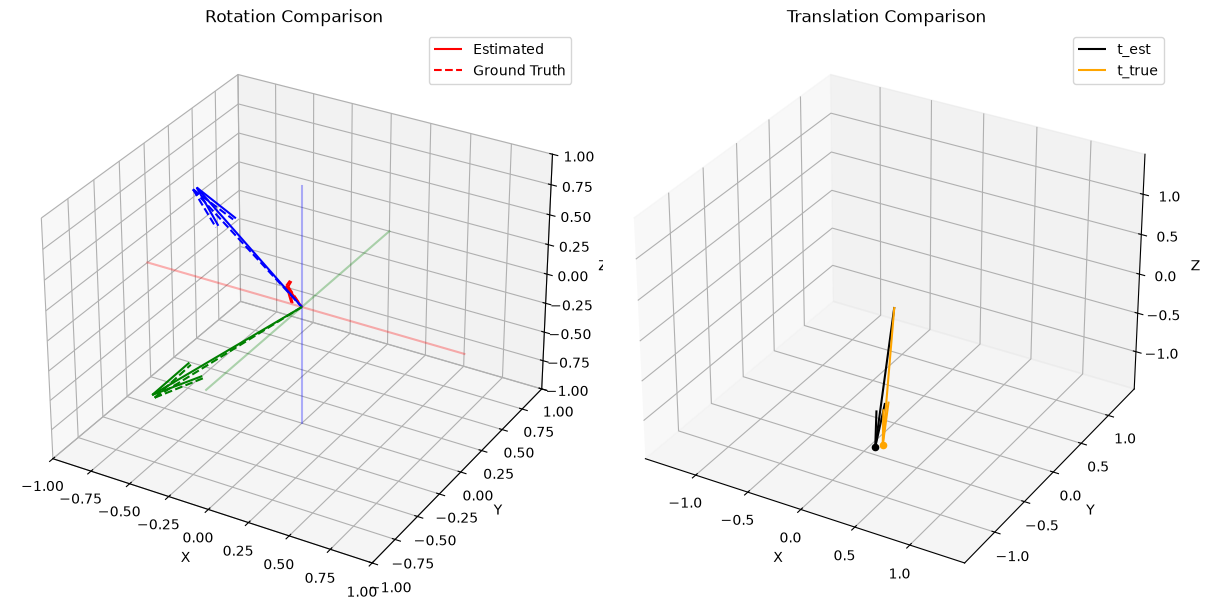

In [5]:
compute_performance(R, R_true, t, t_true, matches, matches_true)
plot_transform_comparison(R, R_true, t, t_true, labels=["Estimated", "Ground Truth", "t_est", "t_true"], scale=1.0)

# Simulated data

## Dataset generation

Run the following cells to generate a dataset of simulated configurations following the procedure presented in the paper.

In [83]:
# Number of configurations to generate
N = 1000

# Overwrite existing files if they exist?
overwrite = True

In [ ]:
room_dim_bounds = [(3, 7),  # x dimension
                   (3, 7),  # y dimension
                   (2.1, 5)]  # z dimension
min_dist_from_walls = 0.5
min_dist_src_mics = 1.0

for n in range(N):

    if not overwrite and os.path.exists(f"simulated_data/room_{n}.json.gz"):
        continue

    room_dim = tuple(np.random.uniform(low, high) for low, high in room_dim_bounds)
    src_pos = (np.random.uniform(min_dist_from_walls, room_dim[0]-min_dist_from_walls),
               np.random.uniform(min_dist_from_walls, room_dim[1]-min_dist_from_walls),
               np.random.uniform(min_dist_from_walls, room_dim[2]-min_dist_from_walls))

    t1 = [np.random.uniform(min_dist_from_walls, room_dim[0]-min_dist_from_walls),
          np.random.uniform(min_dist_from_walls, room_dim[1]-min_dist_from_walls),
          np.random.uniform(min_dist_from_walls, room_dim[2]-min_dist_from_walls)]

    t2 = [np.random.uniform(min_dist_from_walls, room_dim[0]-min_dist_from_walls),
          np.random.uniform(min_dist_from_walls, room_dim[1]-min_dist_from_walls),
          np.random.uniform(min_dist_from_walls, room_dim[2]-min_dist_from_walls)]

    R1 = get_rotation_matrix(deg2rad(np.random.uniform(-180, 180)),
                             deg2rad(np.random.uniform(-180, 180)),
                             deg2rad(np.random.uniform(-180, 180)))

    R2 = get_rotation_matrix(deg2rad(np.random.uniform(-180, 180)),
                             deg2rad(np.random.uniform(-180, 180)),
                             deg2rad(np.random.uniform(-180, 180)))

    # Generate the point clouds and get the ground truth matches
    img1, img2, removed_indices_1, removed_indices_2, matches_pairs, img_sources_perfect = generate_point_clouds(
        room_dim=room_dim,
        src_pos=src_pos,
        R1=R1,
        t1=t1,
        R2=R2,
        t2=t2,
        fs=48000,
        max_order_ism=4,
        sigma_noise=1.0,
        base_ratio_1=0.02,
        max_ratio_1=0.6,
        base_ratio_2=0.02,
        max_ratio_2=0.7,
        max_distance_to_mics=10,
    )

    matches_pairs_json = [
        [int(a), int(b)]
        for a, b in matches_pairs
    ]

    R21, t21 = compute_relative_transformation(R1, t1, R2, t2)

    # Store all calculated values for this configuration in a dict
    room_data = {
        "max_order_ism": 4,
        "geometry": {
            "room_dim": room_dim,
            "pos_src": src_pos,
        },
        "ground_truth": {
            "R1": R1.tolist(),
            "t1": t1,
            "R2": R2.tolist(),
            "t2": t2,
            "R21": R21.tolist(),
            "t21": t21.tolist(),
            "matches_pairs": matches_pairs_json,
        },
        "observations": {
            "img1": img1.tolist(),
            "img2": img2.tolist(),
            "removed_indices_1": removed_indices_1.tolist(),
            "removed_indices_2": removed_indices_2.tolist(),
        },
    }
    
    # Write the contents of this dict to a file named with the number of the room
    os.makedirs("simulated_data", exist_ok=True)
    with gzip.open("simulated_data/room_{:d}.json.gz".format(n), "wt", encoding="utf-8") as f:
        json.dump(room_data, f)